# GL304 · Projeto 1 (VP1): onde a eleição de 2030 vai ser decidida

**Decisor:** a coordenação de uma campanha presidencial, de qualquer partido. O texto não toma lado; os candidatos aparecem só pelo número (13 e 22).
**Pergunta:** em quais municípios vale a pena concentrar tempo e dinheiro de campo em 2030?
**Alternativas:** os 5.570 municípios do Brasil. Há também um bloco com os 645 de SP, onde entram os indicadores do ISDEL.
**Métodos:** soma ponderada e PROMETHEE II, aplicados aos mesmos critérios.

Roteiro, na ordem dos critérios de avaliação:
A. tratamento → B. fusão e validação → F. fontes → ranking → C. mapa → D. barras → E. comparação de mapas → G. ganhos → exportação.

In [1]:
!pip install -q --root-user-action=ignore folium
import json, shutil, subprocess, tempfile, time, urllib.request
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, folium, branca.colormap as cm
from folium import plugins
from scipy.stats import spearmanr

t_inicio = time.perf_counter()
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
# Dados já coletados e consolidados no repositório do grupo (o CSV bruto do TSE tem ~1 GB).
RAW = 'https://raw.githubusercontent.com/atraquia-beep/gl304-ranking-isdel/'
def baixar(caminho, ramo='vp1-dados'):
    with urllib.request.urlopen(RAW + ramo + '/' + caminho) as r:
        return r.read().decode()
sp_raw, br_raw = json.loads(baixar('vp1/dados/sp.json')), json.loads(baixar('vp1/dados/br.json'))
topo_sp, topo_br = json.loads(baixar('vp1/dados/sp-municipios.topo.json')), json.loads(baixar('vp1/dados/br-municipios.topo.json'))
print('SP:', sp_raw['n'], 'municípios | Brasil:', br_raw['n'], 'municípios | gerado em', br_raw['gerado'])

SP: 645 municípios | Brasil: 5570 municípios | gerado em 2026-10-29T00:34:26+00:00


## A. Tratamento dos dados

O arquivo do TSE traz votos por candidato, município e zona. O script [`montar.py`](https://github.com/atraquia-beep/gl304-ranking-isdel/blob/vp1-dados/vp1/dados/montar.py) faz quatro coisas: filtra `NR_TURNO = 2` e `CD_CARGO = 1` (Presidente), tira o exterior (`SG_UF = ZZ`), soma as zonas de cada município e troca o código TSE pelo código IBGE.
Aqui os JSONs viram tabelas e são calculadas as variáveis dos critérios:
- **margem** = (votos 13 − votos 22) / válidos. Positiva quer dizer que o 13 venceu.
- **Δmargem** = margem 2026 − margem 2022.
- **abstenção** = 1 − comparecimento / aptos.

In [2]:
UF = {11:'RO',12:'AC',13:'AM',14:'RR',15:'PA',16:'AP',17:'TO',21:'MA',22:'PI',23:'CE',24:'RN',25:'PB',26:'PE',27:'AL',
      28:'SE',29:'BA',31:'MG',32:'ES',33:'RJ',35:'SP',41:'PR',42:'SC',43:'RS',50:'MS',51:'MT',52:'GO',53:'DF'}

def tabela(d):
    df = pd.DataFrame({'ibge': d['ibge'], 'nome': d['nome']})
    for ano in ('t22', 't26'):
        for k, v in d[ano].items():
            df[f'{k}_{ano[1:]}'] = v
    df['uf'] = (df.ibge // 100000).map(UF)
    for a in ('22', '26'):  # recalculada dos votos (o JSON guarda 5 casas)
        df[f'margem{a}'] = (df[f'13_{a}'] - df[f'22_{a}']) / df[f'validos_{a}']
        assert np.allclose(df[f'margem{a}'], d[f'margem{a}'], rtol=0, atol=1e-5)
    df['virou'] = d['virou']
    df['dmargem'] = df.margem26 - df.margem22
    df['abst26'] = 1 - df.comparecimento_26 / df.eleitorado_26
    return df

br, sp = tabela(br_raw), tabela(sp_raw)

# Limpeza: nada nulo, nada negativo, e no 2º turno os válidos são só 13 + 22 (confirma o filtro de turno).
for nome, df in (('Brasil', br), ('SP', sp)):
    assert df.notna().all().all(), nome
    assert (df.select_dtypes('number') >= -1).all().all(), nome
    for a in ('22', '26'):
        assert (df[f'13_{a}'] + df[f'22_{a}'] == df[f'validos_{a}']).all(), (nome, a)
print('Limpeza ok: sem nulos; 13 + 22 = válidos em todos os municípios (só 2º turno)')
br.head()

Limpeza ok: sem nulos; 13 + 22 = válidos em todos os municípios (só 2º turno)


,ibge,nome,13_22,22_22,validos_22,comparecimento_22,eleitorado_22,13_26,22_26,validos_26,comparecimento_26,eleitorado_26,uf,margem22,margem26,virou,dmargem,abst26
0,1100015,Alta Floresta D'Oeste,3959,9768,13727,14189,19399,4029,10185,14214,14463,18187,RO,-0.423,-0.433,0,-0.010,0.205
1,1100023,Ariquemes,10513,39901,50414,51839,69784,12003,42973,54976,55929,72523,RO,-0.583,-0.563,0,0.020,0.229
2,1100031,Cabixi,1106,2405,3511,3621,4781,1143,2719,3862,3935,4950,RO,-0.370,-0.408,0,-0.038,0.205
3,1100049,Cacoal,12437,37980,50417,51987,66503,14462,40014,54476,55627,69979,RO,-0.507,-0.469,0,0.038,0.205
4,1100056,Cerejeiras,1990,7854,9844,10131,12930,2179,8255,10434,10617,13280,RO,-0.596,-0.582,0,0.013,0.201



Brasil (5570 municípios; médias simples, não ponderadas por eleitor)


,média,mediana,desvio,mín,máx
Margem 2022 (pp),11.800,7.200,37.500,-78.000,87.700
Margem 2026 (pp),7.500,2.200,37.300,-81.100,84.700
Δmargem (pp),-4.300,-4.100,5.600,-31.700,15.200
Abstenção 2026 (%),19.400,19.100,4.400,6.900,41.000



SP (645 municípios; médias simples, não ponderadas por eleitor)


,média,mediana,desvio,mín,máx
Margem 2022 (pp),-18.300,-20.300,16.200,-62.400,44.600
Margem 2026 (pp),-20.000,-22.200,15.100,-60.400,37.200
Δmargem (pp),-1.700,-1.400,4.300,-22.700,8.900
Abstenção 2026 (%),19.700,19.400,2.500,11.700,30.600


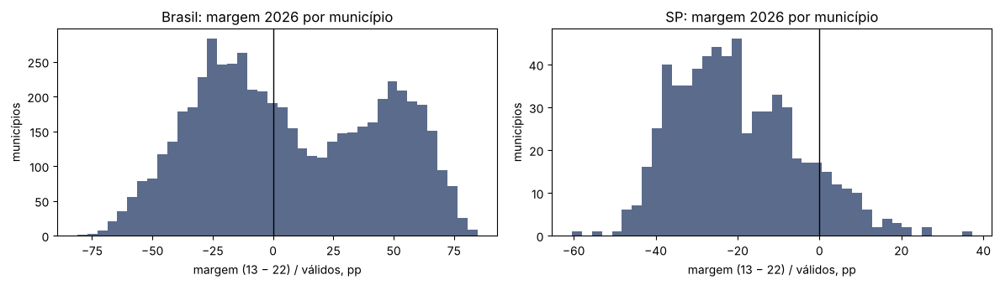

In [3]:
def descritiva(df):
    cols = {'Margem 2022 (pp)': df.margem22 * 100, 'Margem 2026 (pp)': df.margem26 * 100,
            'Δmargem (pp)': df.dmargem * 100, 'Abstenção 2026 (%)': df.abst26 * 100}
    return pd.DataFrame({k: [v.mean(), v.median(), v.std(), v.min(), v.max()] for k, v in cols.items()},
                        index=['média', 'mediana', 'desvio', 'mín', 'máx']).T

for nome, df in (('Brasil', br), ('SP', sp)):
    print(f'\n{nome} ({len(df)} municípios; médias simples, não ponderadas por eleitor)')
    display(descritiva(df).round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=False)
for a, (nome, df) in zip(ax, (('Brasil', br), ('SP', sp))):
    a.hist(df.margem26 * 100, bins=40, color='#5b6b8c')
    a.axvline(0, color='k', lw=1)
    a.set(title=f'{nome}: margem 2026 por município', xlabel='margem (13 − 22) / válidos, pp', ylabel='municípios')
plt.tight_layout(); plt.show()

**Leitura:** o Brasil tem distribuição larga (desvio de ~37 pp), com cidades muito decididas para os dois lados. Em SP a curva fica deslocada para o 22 e é mais estreita.
Para uma campanha, o que importa é a faixa perto de zero, porque ali uma diferença pequena muda o vencedor.

## B. Fusão de fontes e validação

São três fontes, ligadas pelo **código IBGE do município**:
1. **TSE**: votos de 2022 e 2026. Já estão casados com o IBGE em `montar.py`, por UF + nome normalizado, com 13 casos acertados à mão.
2. **IBGE**: lista de municípios (Censo 2022) e malha municipal (polígonos do mapa).
3. **ISDEL**: planilha do professor, só para SP.

Cada `assert` abaixo trava o notebook se a fusão perder ou duplicar algum município.

In [4]:
ids_malha = lambda topo: [g['properties']['ibge'] for g in topo['objects']['municipios']['geometries']]

# TSE × IBGE (malha): merge 1 para 1, todos os municípios dos dois lados
for nome, df, topo, n in (('Brasil', br, topo_br, 5570), ('SP', sp, topo_sp, 645)):
    f = df[['ibge']].merge(pd.DataFrame({'ibge': ids_malha(topo)}), on='ibge', how='outer', validate='1:1', indicator=True)
    assert len(df) == n and df.ibge.is_unique, nome
    assert (f._merge == 'both').all(), f[f._merge != 'both']
    assert ids_malha(topo) == df.ibge.tolist(), 'polígonos na mesma ordem da tabela'
    print(f'{nome}: TSE × malha IBGE = {(f._merge == "both").sum()}/{n}')

# TSE × ISDEL (SP)
isdel = pd.DataFrame(sp_raw['isdel']).assign(ibge=sp_raw['ibge'])
sp = sp.merge(isdel, on='ibge', how='left', validate='1:1', indicator=True)
assert (sp._merge == 'both').all() and sp[['educacao', 'densidade', 'tecido', 'gestao']].notna().all().all()
sp = sp.drop(columns='_merge')
print(f'SP: TSE × ISDEL = {len(sp)}/645')

# Consistência entre os dois recortes: SP dentro do Brasil tem exatamente os mesmos números
b_sp = br[br.uf == 'SP'].reset_index(drop=True)
assert len(b_sp) == 645 and (b_sp[['ibge', '13_26', '22_26', 'eleitorado_26']] == sp[['ibge', '13_26', '22_26', 'eleitorado_26']]).all().all()

# Totais conferidos com o resultado oficial do TSE (SP, 2º turno)
assert (sp['13_26'].sum(), sp['22_26'].sum()) == (12_119_274, 14_139_178)
assert (sp['13_22'].sum(), sp['22_22'].sum()) == (11_519_882, 14_216_587)
print('Totais SP batem com o TSE: 2026 = 12.119.274 × 14.139.178; 2022 = 11.519.882 × 14.216.587')

# Viradas: o vencedor mudou entre 2022 e 2026
for nome, df, esperado in (('Brasil', br, (309, 31, 278)), ('SP', sp, (33, 4, 29))):
    v = df[df.virou == 1]
    got = (len(v), int((v.margem26 > 0).sum()), int((v.margem26 < 0).sum()))
    assert got == esperado, (nome, got)
    print(f'{nome}: {got[0]} viraram ({got[1]} para o 13, {got[2]} para o 22)')

Brasil: TSE × malha IBGE = 5570/5570
SP: TSE × malha IBGE = 645/645
SP: TSE × ISDEL = 645/645
Totais SP batem com o TSE: 2026 = 12.119.274 × 14.139.178; 2022 = 11.519.882 × 14.216.587
Brasil: 309 viraram (31 para o 13, 278 para o 22)
SP: 33 viraram (4 para o 13, 29 para o 22)


## F. Fontes oficiais (acesso em 29/10/2026)

| Dado | Fonte |
|---|---|
| Votos por candidato, município e zona, 2026 e 2022 (TSE, dados abertos) | https://cdn.tse.jus.br/estatistica/sead/odsele/votacao_candidato_munzona/votacao_candidato_munzona_2026.zip (e `_2022.zip`) |
| Aptos, comparecimento e válidos por município e zona, 2026 e 2022 (TSE) | https://cdn.tse.jus.br/estatistica/sead/odsele/detalhe_votacao_munzona/detalhe_votacao_munzona_2026.zip (e `_2022.zip`) |
| Totais oficiais por UF, 2026, usados só na checagem (portal de resultados do TSE) | https://resultados.tse.jus.br/oficial/ele2026/6258/dados/sp/sp-c0001-e006258-u.json |
| Municípios e população, Censo 2022 (IBGE, SIDRA tabela 4714) | https://apisidra.ibge.gov.br/values/t/4714/n6/all/v/93/p/2022 |
| Malha municipal 2022 (IBGE) | https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2022/ |
| ISDEL SP (planilha disponibilizada pelo professor) | https://drive.google.com/uc?export=download&id=1OWOpjw4lU9fN2JYNEYhjM16LFqla0x7_ |

Coleta e montagem: [`vp1/dados/LEIAME.md`](https://github.com/atraquia-beep/gl304-ranking-isdel/blob/vp1-dados/vp1/dados/LEIAME.md).

## Ranking: critérios e métodos

| Critério | Variável | Sentido | Peso |
|---|---|---|---|
| C1 | \|margem 2026\| | menor é melhor (disputa apertada) | 0,30 |
| C2 | eleitores aptos 2026 (log na soma ponderada) | maior é melhor | 0,25 |
| C3 | virou entre 2022 e 2026 (0/1) | maior é melhor | 0,15 |
| C4 | \|Δmargem\| | maior é melhor (eleitorado volátil) | 0,15 |
| C5 | abstenção 2026 | maior é melhor (voto a mobilizar) | 0,15 |

**Bloco SP:** 60% eleitoral (os pesos acima × 0,6) e 40% ISDEL, 0,10 para cada um de Educação, Densidade Empresarial, Tecido Empresarial e Gestão Pública, todos com maior é melhor.
O argumento é que municípios com mais estrutura (empresas, gestão, escolaridade) dão mais retorno por real gasto: há mídia local, lideranças e capacidade de mobilização. Isso é premissa do grupo e por isso vem com a análise de sensibilidade 100/0.

- **Soma ponderada:** normaliza cada critério de 0 a 1 (mín-máx, 1 = melhor) e soma com os pesos. O log em C2 evita que São Paulo capital achate a escala de todo o resto.
- **PROMETHEE II, função usual:** para cada par (a, b) e cada critério, a ganha 1 se for melhor. O fluxo líquido φ é a média ponderada de vitórias menos derrotas. Como só a ordem importa, o log não muda nada aqui.

In [5]:
# Porte em Python de vp1/site/calc.js (somaPonderada e promethee), testado contra o JS mais abaixo.
def soma_ponderada(cols, dirs, pesos):
    s = np.zeros(len(cols[0]))
    for c, d, w in zip(cols, dirs, pesos):
        c = np.asarray(c, float); lo, hi = c.min(), c.max(); r = (hi - lo) or 1
        s += w * ((c - lo) if d > 0 else (hi - c)) / r
    return s

def promethee(cols, dirs, pesos):
    n, tot, phi = len(cols[0]), sum(pesos), np.zeros(len(cols[0]))
    for c, d, w in zip(cols, dirs, pesos):
        v = d * np.asarray(c, float); s = np.sort(v)
        ganha = np.searchsorted(s, v, 'left')            # quantos ele supera
        perde = n - np.searchsorted(s, v, 'right')       # quantos o superam
        phi += w / tot / (n - 1) * (ganha - perde)
    return phi

ELEITORAL = [  # (nome, sentido, peso, variável)
    ('C1 |margem 2026|',      -1, .30, lambda d: d.margem26.abs()),
    ('C2 log(eleitores)',      1, .25, lambda d: np.log(d.eleitorado_26)),
    ('C3 virou',               1, .15, lambda d: d.virou),
    ('C4 |Δmargem|',           1, .15, lambda d: d.dmargem.abs()),
    ('C5 abstenção',           1, .15, lambda d: d.abst26),
]
ISDEL = [(f'I{i} {n}', 1, .10, (lambda c: lambda d: d[c])(c)) for i, (n, c) in
         enumerate([('Educação', 'educacao'), ('Densidade Empresarial', 'densidade'),
                     ('Tecido Empresarial', 'tecido'), ('Gestão Pública', 'gestao')], 1)]
SP_6040 = [(n, s, w * .6, f) for n, s, w, f in ELEITORAL] + ISDEL
assert abs(sum(w for _, _, w, _ in SP_6040) - 1) < 1e-12

def entradas(df, crit):
    return [f(df).to_numpy(float) for *_, f in crit], [s for _, s, _, _ in crit], [w for _, _, w, _ in crit]

def rankear(df, crit):
    cols, dirs, pesos = entradas(df, crit)
    r = df[['ibge', 'nome', 'uf']].copy()
    r['soma'], r['phi'] = soma_ponderada(cols, dirs, pesos), promethee(cols, dirs, pesos)
    for m in ('soma', 'phi'):  # posição 1 = melhor; empate desempata por nome, como em calc.js
        r[f'pos_{m}'] = pd.Series(np.arange(1, len(r) + 1), index=r.sort_values([m, 'nome'], ascending=[False, True]).index)
    return r

t0 = time.perf_counter()
rk_br, rk_sp, rk_sp_100 = rankear(br, ELEITORAL), rankear(sp, SP_6040), rankear(sp, ELEITORAL)
t_ranking = time.perf_counter() - t0
print(f'Rankings calculados em {t_ranking:.2f} s (Brasil 5.570 + SP 645 em dois cenários)')
top = lambda r, m, k=10: r.nsmallest(k, f'pos_{m}')
top(rk_br, 'soma')[['pos_soma', 'nome', 'uf', 'soma', 'pos_phi']]

Rankings calculados em 0.04 s (Brasil 5.570 + SP 645 em dois cenários)


,pos_soma,nome,uf,soma,pos_phi
3242,1,Rio de Janeiro,RJ,0.783,3
303,2,Macapá,AP,0.722,1
3836,3,São Vicente,SP,0.712,2
59,4,Feijó,AC,0.680,7
281,5,Tailândia,PA,0.668,4
3615,6,Mongaguá,SP,0.667,8
160,7,Ananindeua,PA,0.665,49
279,8,Senador José Porfírio,PA,0.662,72
4742,9,Dom Pedrito,RS,0.659,5
4255,10,São João do Triunfo,PR,0.657,252


**Teste do porte:** o mesmo vetor de critérios passa pelo `calc.js` do site, em Node, e pela versão Python. As notas precisam bater em todos os municípios e o top 10 precisa ser idêntico.

In [6]:
if shutil.which('node'):
    tmp = tempfile.mkdtemp()
    open(f'{tmp}/calc.mjs', 'w').write(baixar('vp1/site/calc.js', 'main'))
    js = ("import {somaPonderada, promethee} from './calc.mjs'; import {readFileSync} from 'node:fs';"
          "const p = JSON.parse(readFileSync('entrada.json'));"
          "console.log(JSON.stringify({soma: somaPonderada(p.cols, p.dirs, p.pesos), phi: promethee(p.cols, p.dirs, p.pesos)}));")
    for nome, df, crit, rk in (('Brasil', br, ELEITORAL, rk_br), ('SP 60/40', sp, SP_6040, rk_sp)):
        cols, dirs, pesos = entradas(df, crit)
        json.dump({'cols': [c.tolist() for c in cols], 'dirs': dirs, 'pesos': pesos}, open(f'{tmp}/entrada.json', 'w'))
        out = json.loads(subprocess.run(['node', '--input-type=module', '-e', js], cwd=tmp,
                                        capture_output=True, text=True, check=True).stdout)
        for m in ('soma', 'phi'):
            assert np.allclose(out[m], rk[m], atol=1e-12), (nome, m)
            assert list(np.argsort(-np.array(out[m]), kind='stable')[:10]) == list(top(rk, m).index), (nome, m)
        print(f'{nome}: Python = calc.js nas {len(df)} notas e no top 10 (soma e PROMETHEE)')
else:
    print('Node não encontrado: teste contra o calc.js pulado.')

Brasil: Python = calc.js nas 5570 notas e no top 10 (soma e PROMETHEE)
SP 60/40: Python = calc.js nas 645 notas e no top 10 (soma e PROMETHEE)


## C. Mapa coroplético

A cor indica a faixa de posição no ranking pela soma ponderada; quanto mais escuro, mais prioritário. Clique num município para ver o popup com os critérios. Os pins numerados marcam o top 10.
A malha do Brasil está simplificada (0,6% dos vértices) para o mapa não pesar.

In [7]:
def topo_para_geojson(topo, casas=3):
    # Decodifica TopoJSON (arcos delta-codificados) em GeoJSON; mesma lógica do decodeTopo do calc.js.
    (sx, sy), (tx, ty) = topo['transform']['scale'], topo['transform']['translate']
    arcs = []
    for arc in topo['arcs']:
        x = y = 0; pts = []
        for dx, dy in arc:
            x += dx; y += dy; pts.append([round(x * sx + tx, casas), round(y * sy + ty, casas)])
        arcs.append(pts)
    def anel(idx):
        pts = []
        for k, i in enumerate(idx):
            a = arcs[i] if i >= 0 else arcs[~i][::-1]
            pts += a if k == 0 else a[1:]
        return pts
    feats = []
    for g in topo['objects']['municipios']['geometries']:
        assert g['type'] in ('Polygon', 'MultiPolygon'), g['type']
        coords = [anel(r) for r in g['arcs']] if g['type'] == 'Polygon' else [[anel(r) for r in p] for p in g['arcs']]
        feats.append({'type': 'Feature', 'properties': {'ibge': g['properties']['ibge']},
                      'geometry': {'type': g['type'], 'coordinates': coords}})
    return {'type': 'FeatureCollection', 'features': feats}

pp = lambda x: f'{x * 100:+.1f} pp'
def com_props(topo, df, rk, casas=3):
    gj = topo_para_geojson(topo, casas)
    for f, (_, d), (_, r) in zip(gj['features'], df.iterrows(), rk.iterrows()):
        f['properties'].update(nome=f"{d.nome} ({d.uf})", pos_soma=int(r.pos_soma), pos_phi=int(r.pos_phi),
            margem22=pp(d.margem22), margem26=pp(d.margem26), m26=d.margem26, m22=d.margem22,
            virou='sim' if d.virou else 'não', eleitores=f'{d.eleitorado_26:,}'.replace(',', '.'),
            abst=f'{d.abst26:.1%}')
    return gj

def centro(f):
    g = f['geometry']; aneis = [g['coordinates'][0]] if g['type'] == 'Polygon' else [p[0] for p in g['coordinates']]
    a = np.array(max(aneis, key=len)); return a[:, 1].mean(), a[:, 0].mean()

CAMPOS = ['nome', 'pos_soma', 'pos_phi', 'margem26', 'margem22', 'virou', 'eleitores', 'abst']
ROTULOS = ['Município', 'Posição (soma)', 'Posição (PROMETHEE)', 'Margem 2026', 'Margem 2022', 'Virou?', 'Eleitores 2026', 'Abstenção 2026']

def faixas(n):
    # Faixas de largura igual na legenda (escala linear espremeria o top 10); devolve a legenda e pos -> cor.
    lim = [1, 11, 51, 101, 201, n + 1] if n < 1000 else [1, 11, 101, 501, 1501, n + 1]
    rot = ' | '.join(f'{a}–{b - 1}' for a, b in zip(lim, lim[1:]))
    leg = cm.StepColormap(['#08306b', '#2171b5', '#6baed6', '#c6dbef', '#f2f2f2'], index=range(6), vmin=0, vmax=5,
                          caption=f'Posição no ranking: {rot}', tick_labels=[])
    return leg, lambda pos: leg(np.searchsorted(lim, pos, 'right') - .5)

def camada_ranking(gj, metodo, nome, n, show=True):
    leg, cor = faixas(n)
    return folium.GeoJson(gj, name=nome, show=show,
        style_function=lambda f: {'fillColor': cor(f['properties'][f'pos_{metodo}']), 'color': '#666', 'weight': .3, 'fillOpacity': .85},
        highlight_function=lambda f: {'weight': 2, 'color': '#000'},
        tooltip=folium.GeoJsonTooltip(['nome', f'pos_{metodo}'], aliases=['', 'Posição']),
        popup=folium.GeoJsonPopup(CAMPOS, aliases=ROTULOS, labels=True, max_width=320)), leg

def pins(m, gj, rk, metodo, cor='#d95f02'):
    for i in top(rk, metodo).index:
        f, r = gj['features'][i], rk.loc[i]
        p = f['properties']
        html = (f"<b>{r[f'pos_{metodo}']}º · {p['nome']}</b><table style='font-size:12px'>"
                + ''.join(f'<tr><td>{a}</td><td><b>{p[c]}</b></td></tr>' for c, a in zip(CAMPOS[1:], ROTULOS[1:])) + '</table>')
        folium.Marker(centro(f), popup=folium.Popup(html, max_width=300), tooltip=p['nome'],
            icon=folium.DivIcon(html=f"<div style='background:{cor};color:#fff;border-radius:50%;width:22px;height:22px;"
                                     f"text-align:center;font:bold 12px/22px sans-serif;border:2px solid #fff'>{r[f'pos_{metodo}']}</div>",
                                icon_size=(22, 22), icon_anchor=(11, 11))).add_to(m)

def mapa(gj, rk, metodo, centro_mapa, zoom, titulo):
    m = folium.Map(centro_mapa, zoom_start=zoom)
    camada, cores = camada_ranking(gj, metodo, titulo, len(rk))
    camada.add_to(m); cores.add_to(m); pins(m, gj, rk, metodo)
    folium.LayerControl().add_to(m)
    return m

gj_sp, gj_br = com_props(topo_sp, sp, rk_sp), com_props(topo_br, br, rk_br, casas=2)  # Brasil: 2 casas (~1 km) para o notebook não pesar
mapa(gj_sp, rk_sp, 'soma', [-22.3, -48.6], 7, 'SP: soma ponderada (60% eleitoral / 40% ISDEL)')

In [8]:
mapa(gj_br, rk_br, 'soma', [-14.5, -52], 4, 'Brasil: soma ponderada')

## D. Gráficos de barras

Os gráficos mostram o top 10 de cada método, nos dois recortes, e as viradas por UF.

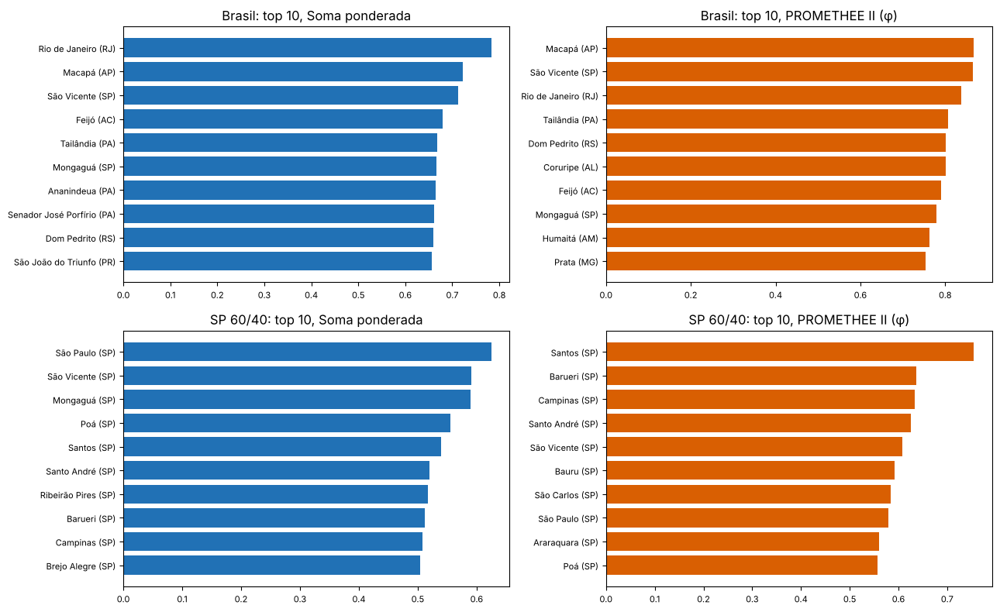

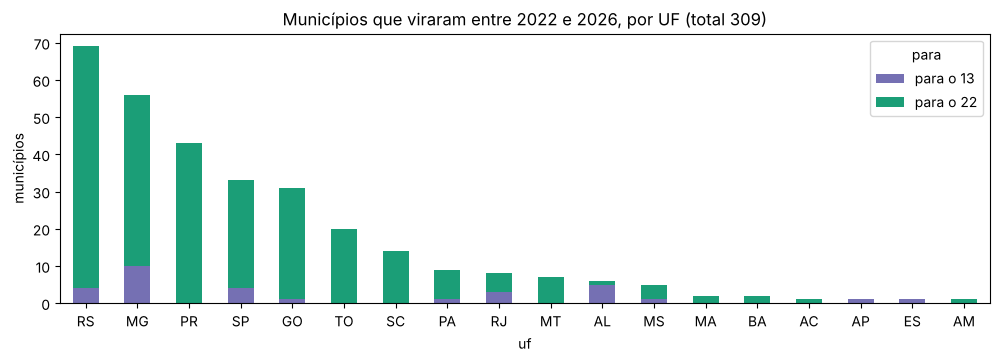

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for linha, (nome, rk) in enumerate((('Brasil', rk_br), ('SP 60/40', rk_sp))):
    for col, (m, rot) in enumerate((('soma', 'Soma ponderada'), ('phi', 'PROMETHEE II (φ)'))):
        t = top(rk, m)[::-1]
        a = ax[linha, col]
        a.barh(t.nome + ' (' + t.uf + ')', t[m], color='#2171b5' if m == 'soma' else '#d95f02')
        a.set_title(f'{nome}: top 10, {rot}'); a.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

v = br[br.virou == 1].assign(para=lambda d: np.where(d.margem26 > 0, 'para o 13', 'para o 22'))
por_uf = v.groupby(['uf', 'para']).size().unstack(fill_value=0)
por_uf = por_uf.loc[por_uf.sum(axis=1).sort_values(ascending=False).index]
por_uf.plot.bar(stacked=True, figsize=(12, 3.5), color=['#7570b3', '#1b9e77'],
                title=f'Municípios que viraram entre 2022 e 2026, por UF (total {len(v)})', ylabel='municípios')
plt.xticks(rotation=0); plt.show()

## E. Comparação de mapas: soma ponderada × PROMETHEE II

SP lado a lado, com o mesmo zoom nos dois mapas. Pelo seletor de camadas dá para trocar o ranking pela margem de 2022 (esquerda) ou de 2026 (direita) e ver onde a disputa mudou.

In [10]:
div = cm.LinearColormap(['#1b9e77', '#f7f7f7', '#7570b3'], vmin=-.4, vmax=.4, caption='Margem (13 − 22) / válidos')
def camada_margem(gj, ano):
    return folium.GeoJson(gj, name=f'Margem {ano}', show=False,
        style_function=lambda f: {'fillColor': div(max(-.4, min(.4, f['properties'][f'm{ano[2:]}']))), 'color': '#666', 'weight': .3, 'fillOpacity': .85},
        tooltip=folium.GeoJsonTooltip(['nome', f'margem{ano[2:]}'], aliases=['', f'Margem {ano}']))

dm = plugins.DualMap(location=[-22.3, -48.6], zoom_start=7)
for lado, metodo, rot, ano in ((dm.m1, 'soma', 'Soma ponderada', '2022'), (dm.m2, 'phi', 'PROMETHEE II', '2026')):
    camada_ranking(gj_sp, metodo, rot, len(rk_sp))[0].add_to(lado)
    camada_margem(gj_sp, ano).add_to(lado)
    pins(lado, gj_sp, rk_sp, metodo)
faixas(len(rk_sp))[0].add_to(dm.m1); div.add_to(dm.m2)
folium.LayerControl(collapsed=False).add_to(dm)
dm

In [11]:
def compara(nome, rk):
    rho = spearmanr(rk.soma, rk.phi).statistic
    a, b = set(top(rk, 'soma').index), set(top(rk, 'phi').index)
    print(f'{nome}: Spearman soma × PROMETHEE = {rho:.2f}; top 10 em comum: {len(a & b)} de 10')
    return rho, len(a & b)

res = {n: compara(n, r) for n, r in (('Brasil', rk_br), ('SP 60/40', rk_sp), ('SP 100/0 (sem ISDEL)', rk_sp_100))}

# Por que divergem no topo: quantos do top 10 de cada método viraram (C3 = 1)?
for nome, df, rk in (('Brasil', br, rk_br), ('SP 60/40', sp, rk_sp)):
    print(f"{nome}: viraram no top 10 da soma = {int(df.loc[top(rk, 'soma').index, 'virou'].sum())}; "
          f"no top 10 do PROMETHEE = {int(df.loc[top(rk, 'phi').index, 'virou'].sum())}")

# Sensibilidade ao ISDEL em SP: quanto o top 10 muda entre 60/40 e 100/0
ab = set(top(rk_sp, 'soma').nome), set(top(rk_sp_100, 'soma').nome)
print(f'\nSP, soma ponderada: top 10 de 60/40 e 100/0 têm {len(ab[0] & ab[1])} municípios em comum')
print('  só no 60/40:', ', '.join(sorted(ab[0] - ab[1])) or '-')
print('  só no 100/0:', ', '.join(sorted(ab[1] - ab[0])) or '-')

Brasil: Spearman soma × PROMETHEE = 0.94; top 10 em comum: 7 de 10
SP 60/40: Spearman soma × PROMETHEE = 0.89; top 10 em comum: 7 de 10
SP 100/0 (sem ISDEL): Spearman soma × PROMETHEE = 0.97; top 10 em comum: 3 de 10
Brasil: viraram no top 10 da soma = 10; no top 10 do PROMETHEE = 10
SP 60/40: viraram no top 10 da soma = 5; no top 10 do PROMETHEE = 2

SP, soma ponderada: top 10 de 60/40 e 100/0 têm 5 municípios em comum
  só no 60/40: Barueri, Campinas, Santo André, Santos, São Paulo
  só no 100/0: Barra do Turvo, Bom Sucesso de Itararé, Itapirapuã Paulista, Paulo de Faria, Ribeirão Branco


**Achados**
1. **No conjunto, os métodos concordam** (Spearman 0,94 no Brasil e 0,89 em SP). **No topo, divergem:** 7 dos 10 primeiros coincidem.
2. **O C3 (virou, 0/1) domina o topo.** No Brasil, os 20 municípios dos dois top 10 viraram; só 5,5% viraram, e esse salto binário pesa 0,15 inteiros. A diferença entre os métodos fica na intensidade: a soma premia distâncias grandes num único critério (Ananindeua é 7º na soma e 49º no PROMETHEE, que só conta quem supera quem).
3. **Em SP, o ISDEL muda a lista.** Com 60/40 entram as cidades grandes e estruturadas (São Paulo, Campinas, Santos, Santo André, Barueri); com 100/0 entram municípios pequenos que viraram. O ISDEL anda junto com o porte da cidade, e o porte já está no C2. A soma 60/40 conta o tamanho duas vezes, o que precisa ser defendido na apresentação.

**Para o decisor:** onde os dois métodos e os dois cenários concordam, a prioridade é robusta. Onde discordam, a lista depende de uma escolha da campanha: dar peso a "já virou uma vez" ou à estrutura do município.

## G. Ganhos

**Tempo.** Para fazer o mesmo à mão, seria preciso consultar o resultado de cada município nos dois anos, anotar os cinco critérios numa planilha, normalizar e ordenar. A estimativa de 3 min por município é uma hipótese do grupo e fica como parâmetro.

In [12]:
MIN_POR_MUNICIPIO = 3          # hipótese: tempo manual por município (consulta + digitação + conferência)
t_total = time.perf_counter() - t_inicio
horas_manual = len(br) * MIN_POR_MUNICIPIO / 60
pd.DataFrame({'Manual (estimado)': [f'{horas_manual:,.0f} h (~{horas_manual / 8:,.0f} dias úteis)', 'alto (digitação de ~28 mil números)', 'refazer tudo'],
              'Programa (medido)': [f'{t_total:,.0f} s (notebook até aqui, com download)', 'baixo: asserts conferem com o TSE', f'{t_ranking:.2f} s para recalcular'],
             }, index=['Tempo para os 5.570 municípios', 'Risco de erro', 'Mudar um peso'])

,Manual (estimado),Programa (medido)
Tempo para os 5.570 municípios,278 h (~35 dias úteis),"7 s (notebook até aqui, com download)"
Risco de erro,alto (digitação de ~28 mil números),baixo: asserts conferem com o TSE
Mudar um peso,refazer tudo,0.04 s para recalcular


**Dinheiro (cenário, não previsão).** O ponto de partida é uma verba de campo hipotética, distribuída proporcionalmente ao eleitorado, que é a regra simples sem ranking.
O cenário pega uma fração da verba dos municípios **já decididos** (|margem 2026| > 20 pp e fora do top 100) e passa para o **top 100** da soma ponderada.
O indicador é o **custo por voto em disputa**, isto é, quantos votos precisariam trocar de lado para inverter o resultado do município: |margem| × válidos / 2.

In [13]:
ORCAMENTO = 100e6     # hipótese: verba de campo total (R$)
FRACAO = 0.30         # hipótese: fração da verba dos municípios decididos que é realocada
LIMIAR = 0.20         # "decidido" = |margem 2026| > 20 pp

base = ORCAMENTO * br.eleitorado_26 / br.eleitorado_26.sum()
top100 = br.index.isin(top(rk_br, 'soma', 100).index)
decidido = (br.margem26.abs() > LIMIAR) & ~top100   # quem cede verba (fora do top 100)
movido = FRACAO * base[decidido].sum()
novo = base.copy()
novo[decidido] *= 1 - FRACAO
novo[top100] += movido * br.eleitorado_26[top100] / br.eleitorado_26[top100].sum()
assert abs(novo.sum() - ORCAMENTO) < 1

em_disputa = (br.margem26.abs() * br.validos_26 / 2)[top100].sum()
brl = lambda x: f'R$ {x:,.0f}'.replace(',', '.')
pd.DataFrame({'Proporcional ao eleitorado': [brl(base[top100].sum()), brl(base[top100].sum() / em_disputa), f'{base[decidido].sum() / ORCAMENTO:.0%}'],
              'Cenário com o ranking': [brl(novo[top100].sum()), brl(novo[top100].sum() / em_disputa), f'{novo[decidido].sum() / ORCAMENTO:.0%}']},
             index=['Verba no top 100', 'R$ por voto em disputa no top 100', 'Verba em municípios decididos']
             ).rename_axis(f'{decidido.sum():,} decididos; realocados {brl(movido)}; {em_disputa:,.0f} votos em disputa no top 100'.replace(',', '.'))

,Proporcional ao eleitorado,Cenário com o ranking
3.761 decididos; realocados R$ 15.777.886; 98.380 votos em disputa no top 100,,
Verba no top 100,R$ 5.241.111,R$ 21.018.997
R$ por voto em disputa no top 100,R$ 53,R$ 214
Verba em municípios decididos,53%,37%


**Leitura:** com a mesma verba total, o top 100 recebe várias vezes mais dinheiro por voto em disputa, e o que sai vem de municípios onde a margem passa de 20 pp, em que esse dinheiro dificilmente muda o resultado.
As três hipóteses (orçamento, fração e limiar) estão no topo da célula e podem ser alteradas. O resultado é ordem de grandeza, não promessa de votos.

## Exportação

O arquivo `ranking.json` fica no mesmo formato colunar do `sp.json` (arrays na ordem do código IBGE), para o site ler depois.

In [14]:
def colunar(rk):
    return {'n': len(rk), 'ibge': rk.ibge.tolist(),
            **{c: [round(x, 6) for x in rk[c]] for c in ('soma', 'phi')},
            **{c: rk[c].astype(int).tolist() for c in ('pos_soma', 'pos_phi')}}
pesos = lambda crit: {n: round(w, 4) for n, _, w, _ in crit}
saida = {'versao': 1, 'gerado': datetime.now(timezone.utc).isoformat(timespec='seconds'),
         'criterios': {'br': pesos(ELEITORAL), 'sp': pesos(SP_6040)},
         'br': colunar(rk_br), 'sp': colunar(rk_sp)}
assert saida['br']['ibge'] == br_raw['ibge'] and saida['sp']['ibge'] == sp_raw['ibge']
json.dump(saida, open('ranking.json', 'w'), ensure_ascii=False, separators=(',', ':'))
print('ranking.json salvo:', saida['br']['n'], 'municípios (Brasil) +', saida['sp']['n'], '(SP)')

ranking.json salvo: 5570 municípios (Brasil) + 645 (SP)
